In [1]:

import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving multi_touch_attribution_data.csv to multi_touch_attribution_data.csv
Dataset shape: (10000, 5)
Columns: ['User ID', 'Timestamp', 'Channel', 'Campaign', 'Conversion']


,User ID,Timestamp,Channel,Campaign,Conversion
0,83281,2025-02-10 07:58:51,Email,New Product Launch,No
1,68071,2025-02-10 23:38:48,Search Ads,Winter Sale,No
2,90131,2025-02-11 10:41:07,Social Media,Brand Awareness,Yes
3,71026,2025-02-10 08:19:44,Direct Traffic,-,Yes
4,94486,2025-02-10 15:15:46,Email,Retargeting,Yes


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [2]:
# CHANGE THESE COLUMN NAMES
USER = "User ID"
TIME = "Timestamp"
CHANNEL = "Channel"
CONVERSION = "Conversion"

# Keep required columns
df = df[[USER, TIME, CHANNEL, CONVERSION]].copy()

# Clean data
df = df.dropna(subset=[USER, TIME, CHANNEL])

# Convert Conversion column to 1 or 0 (since it has 'Yes'/'No' or string representation)
if df[CONVERSION].dtype == 'object':
    df[CONVERSION] = df[CONVERSION].astype(str).str.strip().str.lower().map({'yes': 1, 'no': 0, '1': 1, '0': 0})
else:
    df[CONVERSION] = df[CONVERSION].astype(int)

df[TIME] = pd.to_datetime(df[TIME], errors="coerce")
df = df.dropna(subset=[TIME])

# Sort chronologically
df = df.sort_values([USER, TIME])

# Standardize channel names
df[CHANNEL] = (
    df[CHANNEL]
    .astype(str)
    .str.lower()
    .str.strip()
)

print("Cleaned data:")
display(df.head())

Cleaned data:


,User ID,Timestamp,Channel,Conversion
8297,10028,2025-02-10 01:44:12,search ads,1
3633,10028,2025-02-11 01:03:57,display ads,1
9486,10045,2025-02-10 17:20:43,search ads,0
7663,10045,2025-02-11 18:44:15,display ads,1
8643,10062,2025-02-10 15:42:42,social media,0


In [3]:

def map_channel(channel):

    channel = str(channel).lower()

    if "email" in channel:
        return "E"

    elif any(x in channel for x in [
        "social", "facebook", "instagram",
        "youtube", "linkedin", "twitter"
    ]):
        return "S"

    elif any(x in channel for x in [
        "search", "google", "organic"
    ]):
        return "G"

    else:
        return "N"


df["observation"] = df[CHANNEL].apply(map_channel)

# Add conversion observation at the final
# position for each customer.
#
# This assumes CONVERSION is a customer-level
# final outcome repeated across their records.

def make_sequence(group):

    observations = group["observation"].tolist()

    converted = group[CONVERSION].iloc[-1]

    if converted == 1:
        observations.append("C")
    else:
        observations.append("N")

    return observations


sequences = [
    make_sequence(group)
    for _, group in df.groupby(USER, sort=False)
]

print("Number of customers:", len(sequences))
print("Example sequence:", sequences[0])


Number of customers: 2847
Example sequence: ['G', 'N', 'C']


In [4]:

states = ["Awareness", "Consideration", "Intent"]

observations = ["E", "S", "G", "C", "N"]

N = len(states)
M = len(observations)

state_index = {
    state: i for i, state in enumerate(states)
}

obs_index = {
    obs: i for i, obs in enumerate(observations)
}

# Initial state distribution
pi = np.array([0.60, 0.30, 0.10])

# Transition matrix
A = np.array([
    [0.70, 0.25, 0.05],
    [0.15, 0.60, 0.25],
    [0.05, 0.20, 0.75]
])

# Emission matrix
B = np.array([
    [0.50, 0.30, 0.15, 0.01, 0.04],
    [0.15, 0.25, 0.35, 0.15, 0.10],
    [0.05, 0.10, 0.20, 0.55, 0.10]
])

print("Initial distribution:", pi)
print("Transition matrix:\n", A)
print("Emission matrix:\n", B)


Initial distribution: [0.6 0.3 0.1]
Transition matrix:
 [[0.7  0.25 0.05]
 [0.15 0.6  0.25]
 [0.05 0.2  0.75]]
Emission matrix:
 [[0.5  0.3  0.15 0.01 0.04]
 [0.15 0.25 0.35 0.15 0.1 ]
 [0.05 0.1  0.2  0.55 0.1 ]]


In [5]:

def forward_backward(sequence, pi, A, B):

    obs = [obs_index[x] for x in sequence]

    T = len(obs)
    N = len(pi)

    alpha = np.zeros((T, N))
    beta = np.zeros((T, N))

    # Forward initialization
    alpha[0] = pi * B[:, obs[0]]

    # Forward recursion
    for t in range(1, T):

        alpha[t] = (
            alpha[t-1] @ A
        ) * B[:, obs[t]]

    # Backward initialization
    beta[T-1] = 1.0

    # Backward recursion
    for t in range(T-2, -1, -1):

        beta[t] = A @ (
            B[:, obs[t+1]] * beta[t+1]
        )

    # Smoothed posterior
    gamma = alpha * beta

    gamma = gamma / gamma.sum(
        axis=1, keepdims=True
    )

    # Observation sequence probability
    likelihood = alpha[-1].sum()

    return alpha, beta, gamma, likelihood


In [6]:

customer_sequence = sequences[0]

alpha, beta, gamma, likelihood = (
    forward_backward(
        customer_sequence, pi, A, B
    )
)

print("Customer journey:", customer_sequence)

print("\nBackward probabilities:")
print(beta)

print("\nSmoothed state probabilities:")
print(gamma)

print("\nSequence likelihood:")
print(likelihood)


Customer journey: ['G', 'N', 'C']

Backward probabilities:
[[0.009956 0.025247 0.037949]
 [0.072    0.229    0.443   ]
 [1.       1.       1.      ]]

Smoothed state probabilities:
[[0.20809321 0.61564392 0.17626287]
 [0.05334008 0.47598036 0.47067956]
 [0.00883486 0.24672227 0.74444287]]

Sequence likelihood:
0.004305955


,Awareness,Consideration,Intent,Touchpoint
0,0.208093,0.615644,0.176263,G
1,0.053340,0.475980,0.470680,N
2,0.008835,0.246722,0.744443,C


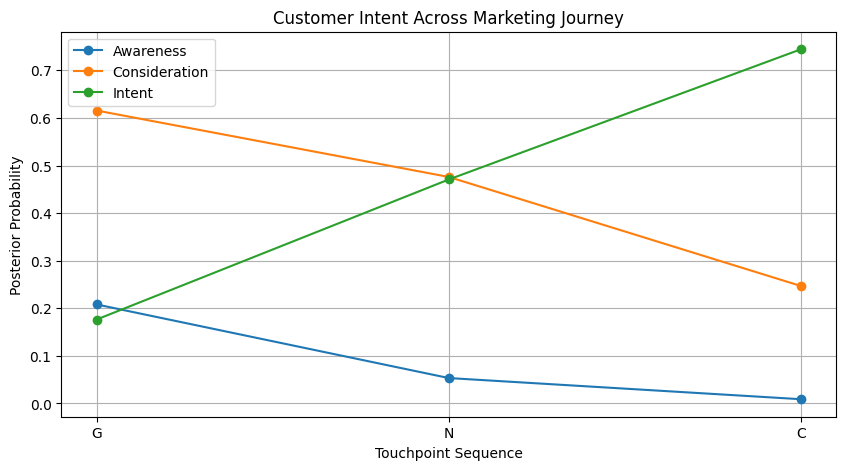

In [7]:

import matplotlib.pyplot as plt

posterior_df = pd.DataFrame(
    gamma,
    columns=states
)

posterior_df["Touchpoint"] = customer_sequence

display(posterior_df)

posterior_df[states].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Customer Intent Across Marketing Journey")
plt.xlabel("Touchpoint Sequence")
plt.ylabel("Posterior Probability")
plt.xticks(
    range(len(customer_sequence)),
    customer_sequence
)
plt.grid(True)
plt.show()


In [8]:

# Scaled Forward-Backward Algorithm

def scaled_fb(seq, pi, A, B):

    obs = [obs_index[x] for x in seq]

    T = len(obs)
    N = len(pi)

    alpha = np.zeros((T, N))
    beta = np.zeros((T, N))
    scales = np.zeros(T)

    # Forward initialization
    alpha[0] = pi * B[:, obs[0]]
    scales[0] = alpha[0].sum()
    alpha[0] /= scales[0]

    # Forward recursion
    for t in range(1, T):

        alpha[t] = (
            alpha[t-1] @ A
        ) * B[:, obs[t]]

        scales[t] = alpha[t].sum()

        alpha[t] /= scales[t]

    # Backward initialization
    beta[-1] = 1.0

    # Backward recursion
    for t in range(T-2, -1, -1):

        beta[t] = A @ (
            B[:, obs[t+1]] * beta[t+1]
        )

        beta[t] /= scales[t+1]

    # State posterior
    gamma = alpha * beta

    gamma /= gamma.sum(
        axis=1, keepdims=True
    )

    # Pairwise transition posterior
    xi = np.zeros((T-1, N, N))

    for t in range(T-1):

        value = (
            alpha[t, :, None]
            * A
            * B[:, obs[t+1]][None, :]
            * beta[t+1][None, :]
        )

        xi[t] = value / value.sum()

    loglik = np.sum(np.log(scales))

    return gamma, xi, loglik


# Baum-Welch / EM training

def train_hmm(sequences, iterations=20):

    pi = np.array([0.60, 0.30, 0.10])

    A = np.array([
        [0.70, 0.25, 0.05],
        [0.15, 0.60, 0.25],
        [0.05, 0.20, 0.75]
    ])

    B = np.array([
        [0.50, 0.30, 0.15, 0.01, 0.04],
        [0.15, 0.25, 0.35, 0.15, 0.10],
        [0.05, 0.10, 0.20, 0.55, 0.10]
    ])

    eps = 1e-10
    history = []

    for iteration in range(iterations):

        pi_count = np.zeros(N)
        trans_count = np.zeros((N, N))
        state_count = np.zeros(N)
        emission_count = np.zeros((N, M))

        total_loglik = 0.0

        # E-step
        for seq in sequences:

            gamma, xi, loglik = scaled_fb(
                seq, pi, A, B
            )

            total_loglik += loglik

            pi_count += gamma[0]

            for t in range(len(seq)):

                k = obs_index[seq[t]]

                emission_count[:, k] += gamma[t]
                state_count += gamma[t]

            if len(seq) > 1:

                trans_count += xi.sum(axis=0)

        # M-step
        pi = pi_count / pi_count.sum()

        A = trans_count / (
            trans_count.sum(axis=1, keepdims=True)
            + eps
        )

        B = emission_count / (
            state_count[:, None] + eps
        )

        history.append(total_loglik)

        print(
            f"Iteration {iteration+1}: "
            f"Log likelihood = {total_loglik:.4f}"
        )

    return pi, A, B, history


# Train the model
pi, A, B, history = train_hmm(
    sequences,
    iterations=20
)

print("\nLearned Initial Distribution:")
print(pi)

print("\nLearned Transition Matrix:")
print(A)

print("\nLearned Emission Matrix:")
print(B)


Iteration 1: Log likelihood = -25901.2531
Iteration 2: Log likelihood = -17446.0322
Iteration 3: Log likelihood = -17375.6865
Iteration 4: Log likelihood = -17312.5141
Iteration 5: Log likelihood = -17256.9180
Iteration 6: Log likelihood = -17210.3053
Iteration 7: Log likelihood = -17173.1834
Iteration 8: Log likelihood = -17144.8158
Iteration 9: Log likelihood = -17123.6814
Iteration 10: Log likelihood = -17108.0749
Iteration 11: Log likelihood = -17096.4922
Iteration 12: Log likelihood = -17087.7665
Iteration 13: Log likelihood = -17081.0544
Iteration 14: Log likelihood = -17075.7685
Iteration 15: Log likelihood = -17071.5055
Iteration 16: Log likelihood = -17067.9889
Iteration 17: Log likelihood = -17065.0278
Iteration 18: Log likelihood = -17062.4891
Iteration 19: Log likelihood = -17060.2785
Iteration 20: Log likelihood = -17058.3286

Learned Initial Distribution:
[6.62404747e-01 3.37565094e-01 3.01595499e-05]

Learned Transition Matrix:
[[0.4296034  0.48932565 0.08107094]
 [0.029

In [9]:

# Analyze one customer journey

customer_sequence = sequences[0]

gamma, xi, loglik = scaled_fb(
    customer_sequence, pi, A, B
)

results = pd.DataFrame(
    gamma,
    columns=states
)

results["Touchpoint"] = customer_sequence

print("Customer Journey:")
display(results)

print("Sequence Log Likelihood:", loglik)


Customer Journey:


,Awareness,Consideration,Intent,Touchpoint
0,5.221402e-01,0.477838,0.000022,G
1,5.492539e-02,0.557904,0.387170,N
2,8.982580e-09,0.003059,0.996941,C


Sequence Log Likelihood: -4.471305408466433


,Awareness,Consideration,Intent
Channel,,,
C,9.699740e-09,0.002757,0.997243
E,3.753178e-01,0.408389,0.216293
G,3.455733e-01,0.498324,0.156103
N,2.561572e-01,0.444015,0.299828
S,3.581620e-01,0.469225,0.172613


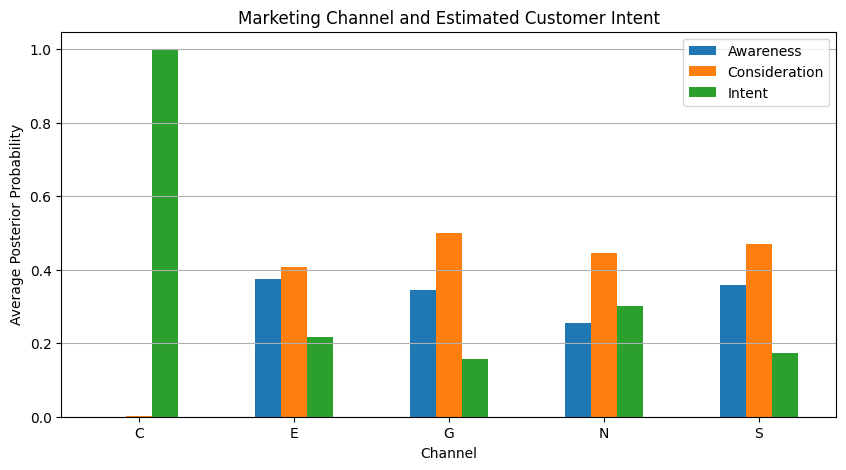

In [10]:

channel_results = []

for seq in sequences:

    gamma, xi, loglik = scaled_fb(
        seq, pi, A, B
    )

    for t, event in enumerate(seq):

        channel_results.append({
            "Channel": event,
            "Awareness": gamma[t, 0],
            "Consideration": gamma[t, 1],
            "Intent": gamma[t, 2]
        })

channel_df = pd.DataFrame(channel_results)

summary = channel_df.groupby(
    "Channel"
)[states].mean()

display(summary)

summary.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Marketing Channel and Estimated Customer Intent")
plt.ylabel("Average Posterior Probability")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()
